# Point - Edge Interactions 

In [1]:
#using Revise

## Import Packages

In [14]:
using StaticArrays 
using LinearAlgebra # provides the function norm 
using HCubature # provides adaptive numerical integration 

using Test # provides testing functionality 
using Plots

function hcubature_count(f, a, b; kws...)
    count = 0
    i = hcubature(a, b; kws...) do x
        count += 1
        # display(count)
        f(x)
    end
    return (i..., count)
end

const Point2D = SVector{2,Float64};
const Point3D = SVector{3,Float64};

include("edge_struct_definitions.jl"); # how to get rid of the semi-colom here? 

# provides integral I3 for point - edge interactions 
include("theorem2_nonhomogeneous_integrals.jl");   

## Section 1: Introduction

We wish to develop a package for the computation of point - edge interactions. This package should contain both analytical and numerical methods and enabling plotting the integrand. 

**Point-Edge Pair** Assume given a point $\mathbf{a}$. Assume given an edge $\ell$ with end-points $\mathbf{r}_1$ and $\mathbf{r}_2$, length $|\ell| = \| \mathbf{r}_2 - \mathbf{r}_1 \|$, directional vector $\mathbf{\tau} = ( \mathbf{r}_2 - \mathbf{r}_1 ) / |\ell|$  and the scaled directional vector $\mathbf{e} = ( \mathbf{r}_2 - \mathbf{r}_1 ) / |\ell|^2$. Assume that $\varphi_1(\mathbf{r})$ and $\varphi_2(\mathbf{r})$ to be the two linear Lagrange shape function defined on $\ell$ centered in $\mathbf{r}_1$ and $\mathbf{r}_2$, respectively, i.e., 

$$
\varphi_1(\mathbf{r}) = \frac{(\mathbf{r}_2 - \mathbf{r},\tau)}{(\mathbf{r}_2 - \mathbf{r}_1,\tau)}
\text{ and }
\varphi_2(\mathbf{r}) = \frac{(\mathbf{r} - \mathbf{r}_1,\tau)}{(\mathbf{r}_2 - \mathbf{r}_1,\tau)} \, . 
$$

**Point-Edge Interaction** We seek to compute the point - edge interaction defined by 

$$ 
K_1(\mathbf{a},\ell) 
= \int_{\ell} \frac{1}{\| \mathbf{r} - \mathbf{a} \|} \, d\ell \, , 
$$

as well as the variants weighted with the basis functions  

$$ 
K_2^{\varphi_1}(\mathbf{a},\ell) 
= \int_{\ell} \frac{\varphi_1(\mathbf{r}(s))}{\| \mathbf{r} - \mathbf{a} \|} \, d\ell
\text{ and }
K_2^{\varphi_2}(\mathbf{a},\ell) 
= \int_{\ell} \frac{\varphi_2(\mathbf{r}(s))}{\| \mathbf{r} - \mathbf{a} \|} \, d\ell \, . 
$$

The integrals $K_1(\mathbf{a},\ell)$ and $K_2^{\varphi_i}(\mathbf{a},\ell)$ are singular for $\mathbf{a} \in \ell$. Adaptive numerical integration will thus require more evaluations of the integrand as the distance between $\mathbf{a}$ and $\ell$ decreases.

**Point-Edge Implementation** 

We use [function-like-objects](https://docs.julialang.org/en/v1/manual/methods/#Function-like-objects) to define the shape functions $\varphi_1(\mathbf{r})$ and $\varphi_2(\mathbf{r})$ associated with the edge. 

## Section 2: Computing Point - Edge Interaction

### Parametrization of the Edge  

Assume $\mathbf{r} \in \ell$. In using numerical quadrature along $\ell$, we use the parametrization 

$$
\mathbf{r}(\lambda) \in \ell \Leftrightarrow 
\mathbf{r}(\lambda) = \mathbf{r}_1 + \lambda \, |\ell| \, \mathbf{\tau} \text{ for } 0 \leq \lambda \leq 1
$$

(observe the presence of $|\ell|$). The tangent vector is thus given by 

$$
\frac{d \, \mathbf{r}(\lambda)}{d\lambda} = |\ell| \, \mathbf{\tau} \, . 
$$

### Parametrization of Point - Edge Distance  

In analytical methods, the distance from $\mathbf{a}$ to a point $\mathbf{r} \in \ell$ is decomposed in a component perpendicular to $\ell$ and a component along $\ell$. The distance perpendicular to $\ell$ can be computed as 

$$
R_0 = \| (\mathbf{r}_1 - \mathbf{a}) \times \tau \| = \| (\mathbf{r}_2 - \mathbf{a}) \times \tau \| \, . 
$$ 

The distance along $\ell$ is computed as 
  
$$
s(\mathbf{r}) = (\mathbf{r} - \mathbf{a}) \cdot \tau \, . 
$$

The variabele $s$ is bounded by $s_1 \leq s \leq s_2$ where $s_1 = (\mathbf{r}_1 - \mathbf{a}) \cdot \tau$ and $s_2 = (\mathbf{r}_2 - \mathbf{a}) \cdot \tau$, respectively. The Jacobian is given by 

$$
\frac{d \, s(\lambda)}{d\lambda} 
= \frac{d}{d\lambda} (\mathbf{r}(\lambda) - \mathbf{a}, \tau) 
= (\frac{d \mathbf{r}(\lambda)}{d\lambda}, \tau)
= (|\ell| \, \tau, \tau) = |\ell| \, . 
$$ 

The distance from $\mathbf{a}$ to $\mathbf{r} \in \ell$ is thus equal to  

$$
\mathbf{r} \in \ell \Leftrightarrow 
\| \mathbf{r} - \mathbf{a} \| = \sqrt{R_0^2+s^2} \, . 
$$

### Calculation of $K_1$

We arrive at the following closed form expression for $K_1$ (see e.g. Morandi-2010 Eqn. (27)) 

$$ 
K_1(\mathbf{a},\ell) 
= \int_{\ell} \frac{1}{\| \mathbf{r} - \mathbf{a} \|} \, d\ell 
= \int_{s_1}^{s_2} \frac{1}{\sqrt{R_0^2+s^2}} \, ds
= \log \left( \frac{\|\mathbf{a} - \mathbf{r}_2\|+\|\mathbf{a} - \mathbf{r}_1\|+\|\mathbf{r}_2 - \mathbf{r}_1\|}{\|\mathbf{a} - \mathbf{r}_2\|+\|\mathbf{a} - \mathbf{r}_1\|-\|\mathbf{r}_2 - \mathbf{r}_1\|} \right) \, . 
$$

Using quadrature we arrive at the expression 

$$
K_1(\mathbf{a},\ell) 
= \int_{\ell} \frac{1}{\| \mathbf{r} - \mathbf{a} \|} \, d\ell
= \int_{s_1}^{s_2} \frac{1}{\sqrt{R_0^2+s^2}} \, ds
= |\ell| \int_0^1 \frac{1}{\| \mathbf{r}(\lambda) - \mathbf{a} \|} \, d\lambda \, . 
$$

### A Reference Result for $K_1$ 

Assume the edge $\ell$ to extend along the $x$-axis from $\mathbf{r}_1 = (-1,0)$ to $\mathbf{r}_2 = (1,0)$. A point on $\ell$ then has coordinates $\mathbf{r}_1 = (x,0)$ with $-1 \leq x \leq 1$. Assume the point $\mathbf{a}$ to be located on the $y$-axis above $\ell$ with coordinates $\mathbf{a} = (0,1)$. Then the distance can be expressed as $\| \mathbf{r} - \mathbf{a} \|$ can be expressed as $\| \mathbf{r} - \mathbf{a} \| = \sqrt{x^2+1}$ with $-1 \leq x \leq 1$. Then 

$$ 
K_1(\mathbf{a},\ell) 
= \int_{-1}^{1} \frac{1}{\sqrt{x^2+1}} \, dx
= \left[ \text{asinh}(x) \right]_{x=-1}^{x=1} = 2 \, \text{asinh}(1) = 1.7627 \ldots \, . 
$$

At the same time we have that 

$$ 
K_1(\mathbf{a},\ell) 
= \log \left( \frac{\sqrt{2}+\sqrt{2}+2}{\sqrt{2}+\sqrt{2}-2} \right) 
= \log \left( \frac{\sqrt{2}+1}{\sqrt{2}-1} \right) = 1.7627 \ldots \, . 
$$

### Calculation of $K_2$

We compute  

$$ 
K_2^{\varphi_2}(\mathbf{a},\ell) 
= \int_{\ell} \frac{\varphi_2(\mathbf{r}(s))}{\| \mathbf{r} - \mathbf{a} \|} \, d\ell
= \int_{s_1}^{s_2} \frac{\varphi_2(\mathbf{r}(s))}{\sqrt{R_0^2+s^2}} \, ds 
= \frac{\|\mathbf{r}_2 - \mathbf{a}\| - \|\mathbf{r}_1 - \mathbf{a}\| - s_1 K_1(\mathbf{a},\ell)}{\|\mathbf{r}_2 - \mathbf{r}_1\|} \, . 
$$  

Using quadrature we arrive at the expression 

$$
K_2^{\varphi_2}(\mathbf{a},\ell) 
= \frac{|\ell|}{(\mathbf{r}_2 - \mathbf{r}_1,\tau)} \int_0^1 \frac{(\mathbf{r}(\lambda) - \mathbf{r}_1,\tau)}{\| \mathbf{r}(\lambda) - \mathbf{a} \|} \, d\ell \, .
$$

### A Reference Computation for $K_2$

For the same test case as above, we have that 

$$
K_2^{\varphi_2}(\mathbf{a},\ell) = 0.5 * K_1(\mathbf{a},\ell) = 0.8814 \ldots \, . 
$$

### Sandbox 

We also introduce for further use 

$$
R(\mathbf{a},\ell, h) = \int_{\ell} f_1(h,\| \mathbf{r} - \mathbf{a} \|) \, d\ell = [I_8(s,h,R_0)]_{s=s_1}^{s=s_2} = [J_{0,1}(s,h,R_0)]_{s=s_1}^{s=s_2} \, . 
$$

## Section 3: First Test Case    

In [76]:
function K1(a::Point3D,e::Edge3D) 
    numer = norm(e.r2-a) + norm(e.r1-a) + norm(e.r2-e.r1)  
    denom = norm(e.r2-a) + norm(e.r1-a) - norm(e.r2-e.r1)
    if (denom==0.)
        error("K1: division by zero")
    else 
        ans = log(numer/denom) 
    end 
    return ans    
end; 

function K1integrand(lmbd,a::Point3D,e::Edge3D) 
    r  = e.r1+lmbd*e.len*e.tau
    return e.len/norm(r-a)  
end; 

function K2(a::Point3D,e::Edge3D) 
    s1 = dot(e1.r1-a,e1.tau)
    numer = norm(e.r2-a) - norm(e.r1 - a) - s1*K1(a,e)   
    denom = norm(e.r2-e.r1)
    return numer/denom   
end; 

function K2integrand(lmbd,a::Point3D,e::Edge3D) 
    r  = e.r1+lmbd*e.len*e.tau
    return e.len*e(r)[2]/norm(r-a)   
end; 

In [77]:
# set point 
a = Point3D(0.,1.,0.); 

# set edge 
r11 = Point3D(-1.,0.,0.); r12 = Point3D(1.,0.,0.); 
e1 = Edge3D(r1 = r11,r2 = r12)

[K1(a,e1), K2(a,e1)]

2-element Vector{Float64}:
 1.7627471740390857
 0.8813735870195428

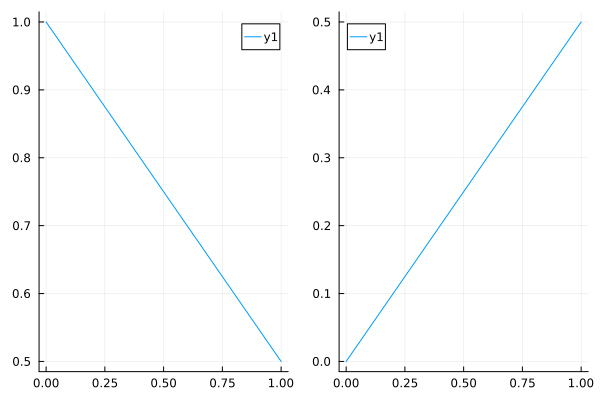

In [78]:
# plot shape function defined on the edge 
lmdvec = Vector(0:0.01:1) 
rvec = [r11 + lmd*r12  for lmd in lmdvec]
p1 = plot(lmdvec,[elem[1] for elem in e1.(rvec)])
p2 = plot(lmdvec,[elem[2] for elem in e1.(rvec)])
plot(p1,p2, layout=(1,2))

In [79]:
K1val = K1(a,e1)
K2val = K2(a,e1)
[K1val, K2val]
K1valnum = hcubature(s -> K1integrand(s[1],a,e1), (0,), (1,))[1]
K2valnum = hcubature(s -> K2integrand(s[1],a,e1), (0,), (1,))[1]
@test K1val ≈ K1valnum 

Test Passed

## Section 4: Second Test Case   

In [80]:
# set point 
a = Point3D(0.,0.,1.); 

# set edge 
r11 = Point3D(1.,1.,0.); r12 = Point3D(2.,2.,0.); 
e1 = Edge3D(r1 = r11,r2 = r12)

[K1(a,e1), K2(a,e1)]

2-element Vector{Float64}:
 0.6165313392584972
 0.2800441329095564

In [81]:
K1val = K1(a,e1)
K2val = K2(a,e1)
K1valnum = hcubature(s -> K1integrand(s[1],a,e1), (0,), (1,))[1]
K2valnum = hcubature(s -> K2integrand(s[1],a,e1), (0,), (1,))[1]
@test K1val ≈ K1valnum 
@test K2val ≈ K2valnum

Test Passed

## Section 5: Exploring the Number of Iterand Evaluations 

We explore the number of function evaluations as the distance to the edge decreases. 

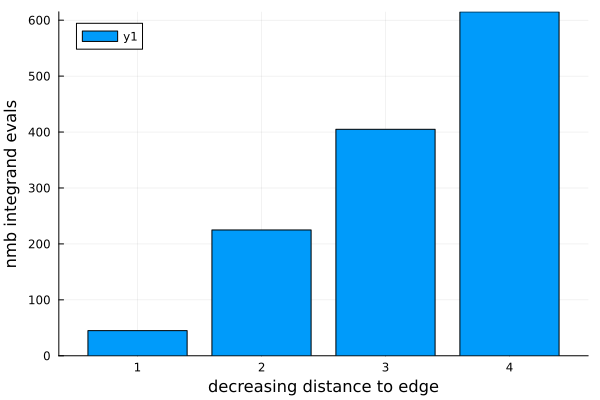

In [87]:
# set edge 
r11 = Point3D(-1.,0.,0.); r12 = Point3D(1.,0.,0.); 
e1 = Edge3D(r1 = r11,r2 = r12)

distance_to_edge = [1., 1e-1, 1e-2, 1e-3]
number_integrand_evals = similar(distance_to_edge)

for (i,di) in enumerate(distance_to_edge)
    
    # set point 
    a = Point3D(0.,di,0.); 

    number_integrand_evals[i] = hcubature_count(s -> K1integrand(s[1],a,e1), (0,), (1,))[3]
    
end 

bar(number_integrand_evals,xlabel="decreasing distance to edge",ylabel="nmb integrand evals")
